# TP1 — Noyaux de convolution

**Cours :** Réseaux de neurones convolutifs (CNN) — 30 h — Master 1 SDIA
**Enseignante :** Dr. Noulapeu Ngaffo Armielle — ENSPD, Université de Douala
**Durée conseillée :** 1 h 30  ·  **Barème :** 10 points

---

## Objectifs

- Manipuler une image comme une matrice de nombres.
- Construire et reconnaître les noyaux classiques (flou, netteté, contours, relief).
- Appliquer un noyau et interpréter la carte d'activation obtenue.
- Vérifier « à la main » le résultat d'une convolution sur une petite matrice.

## Travail demandé

1. Répondre aux 3 questions de la section « À vous ».
2. Rendre le notebook exécuté (toutes les cellules doivent avoir tourné sans erreur).

## Mode d'emploi

- Exécuter les cellules **dans l'ordre** (`Shift + Entrée`).
- Les cellules marquées **« À vous »** sont à compléter : ce sont elles qui sont évaluées.
- Toutes les figures s'affichent dans le notebook ; si ce n'est pas le cas, vérifier que la
  première cellule a bien été exécutée.
- Reproductibilité : les graines aléatoires sont fixées. Deux exécutions donnent le même résultat.


In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
np.random.seed(4112)

## 1. Une image, c'est une matrice

On charge une image réelle en niveaux de gris et on l'affiche.

dimensions : (768, 1024)
valeurs   : min = 0, max = 250


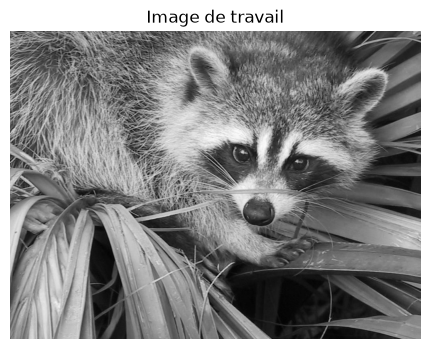

In [2]:
img = np.load("../data/face_gray.npy").astype(float)
print("dimensions :", img.shape)
print("valeurs   : min = %.0f, max = %.0f" % (img.min(), img.max()))

plt.figure(figsize=(6, 4))
plt.imshow(img, cmap="gray")
plt.title("Image de travail")
plt.axis("off")
plt.show()

## 2. Les noyaux de convolution

Un **noyau** (ou *filtre*) est une petite matrice. Appliqué par balayage sur l'image, il
produit une nouvelle image. Voici les noyaux classiques.

In [3]:
noyaux = {
    "flou (moyenneur)": np.ones((3, 3)) / 9,
    "flou gaussien":    np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]]) / 16,
    "nettete":          np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]]),
    "contours (Sobel X)": np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]]),
    "contours (Sobel Y)": np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]]),
    "laplacien":        np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]]),
    "relief (emboss)":  np.array([[-2, -1, 0], [-1, 1, 1], [0, 1, 2]]),
}
for nom, k in noyaux.items():
    print(f"{nom:>22} :\n{k}\n")

      flou (moyenneur) :
[[0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]]

         flou gaussien :
[[0.0625 0.125  0.0625]
 [0.125  0.25   0.125 ]
 [0.0625 0.125  0.0625]]

               nettete :
[[ 0 -1  0]
 [-1  5 -1]
 [ 0 -1  0]]

    contours (Sobel X) :
[[-1  0  1]
 [-2  0  2]
 [-1  0  1]]

    contours (Sobel Y) :
[[-1 -2 -1]
 [ 0  0  0]
 [ 1  2  1]]

             laplacien :
[[ 0  1  0]
 [ 1 -4  1]
 [ 0  1  0]]

       relief (emboss) :
[[-2 -1  0]
 [-1  1  1]
 [ 0  1  2]]



## 3. Appliquer un noyau : `scipy.signal.convolve2d`

> **Attention à la convention.** `convolve2d` effectue une *vraie* convolution : le noyau est
> retourné avant d'être appliqué. Les réseaux de neurones utilisent la **corrélation croisée**
> (noyau non retourné). Pour un noyau symétrique, les deux coïncident.

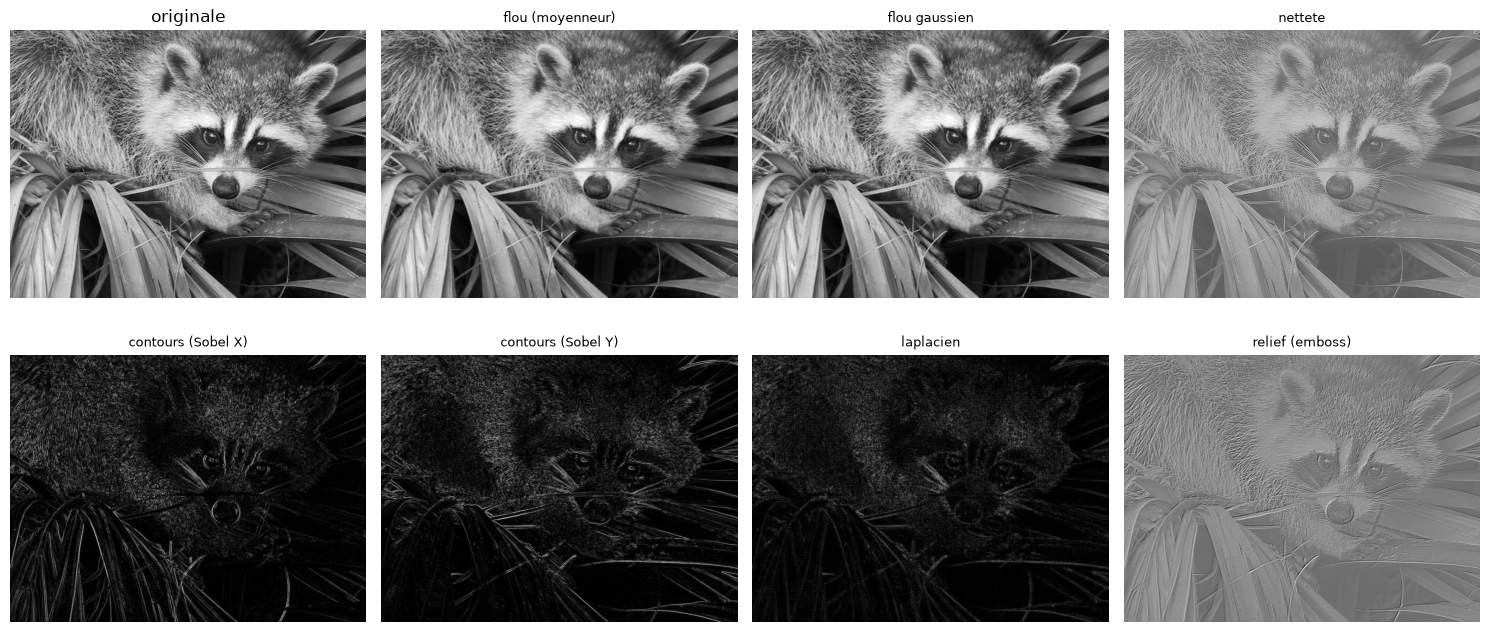

In [4]:
from scipy import signal

# correlation=True : convention des CNN (noyau NON retourne)
# correlation=False : vraie convolution (noyau retourne)
def applique(im, noyau, correlation=True):
    k = noyau if correlation else noyau[::-1, ::-1]
    return signal.convolve2d(im, k, mode="same", boundary="symm")

fig, axes = plt.subplots(2, 4, figsize=(15, 7))
axes = axes.ravel()
axes[0].imshow(img, cmap="gray"); axes[0].set_title("originale")
for ax, (nom, k) in zip(axes[1:], noyaux.items()):
    r = applique(img, k)
    ax.imshow(np.abs(r) if "contours" in nom or "laplacien" in nom else r, cmap="gray")
    ax.set_title(nom, fontsize=9)
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Vérification du calcul, à la main

Avant de faire confiance à une bibliothèque, on refait le calcul soi-même sur une petite
matrice. Le **premier élément** de la sortie vaut $\sum (\text{zone} \times \text{noyau})$.

In [5]:
I = np.array([[1, 2, 0, 1, 3],
              [4, 5, 1, 0, 2],
              [2, 3, 6, 1, 1],
              [0, 1, 4, 8, 2],
              [1, 2, 1, 3, 5]], dtype=float)
K = np.array([[1, 0, -1],
              [1, 0, -1],
              [1, 0, -1]], dtype=float)

zone = I[:3, :3]
print("zone examinee :\n", zone)
print("produits terme a terme :", (zone * K).ravel())
print("premier element de sortie =", (zone * K).sum())

# comparaison avec scipy
S = signal.convolve2d(I, K[::-1, ::-1], mode="valid")  # correlation croisee
print("\nsortie complete (correlation croisee) :\n", S)

zone examinee :
 [[1. 2. 0.]
 [4. 5. 1.]
 [2. 3. 6.]]
produits terme a terme : [ 1.  0. -0.  4.  0. -1.  2.  0. -6.]
premier element de sortie = 0.0

sortie complete (correlation croisee) :
 [[ 0.  8.  1.]
 [-5.  0.  6.]
 [-8. -6.  3.]]


## 5. À vous

**Question 1.** Le noyau ci-dessous détecte-t-il plutôt les contours horizontaux ou
verticaux ? Répondez en une phrase, puis vérifiez en l'appliquant.

**Question 2.** Construisez un noyau 5×5 qui floute l'image plus fortement que le
moyenneur 3×3, puis appliquez-le.

**Question 3.** Que se passe-t-il si la somme des coefficients d'un noyau vaut 0 ?
Testez sur une zone uniforme de l'image.

In [6]:
# ---- À VOUS (question 1) ----
K1 = np.array([[-1, -2, -1],
               [ 0,  0,  0],
               [ 1,  2,  1]])
# votre reponse en commentaire :
# ...

# ---- À VOUS (question 2) ----
K2 = None   # a completer : np.ones((5,5))/25 par exemple

# ---- À VOUS (question 3) ----
# appliquez un noyau de somme nulle a une zone uniforme et expliquez :
# ...

## 6. Synthèse

| Ce qu'il faut retenir | |
|---|---|
| Un noyau de moyenne = **flou** | la somme des coefficients vaut 1 |
| Un noyau de différence = **contours** | la somme des coefficients vaut 0 |
| Le résultat s'appelle une **carte d'activation** | c'est ce que le réseau apprendra à produire |
| La convolution est **locale** | chaque pixel de sortie ne dépend que du voisinage |

**Suite :** le TP2 aborde le padding, le stride et le pooling.